<div class="alert alert-info">
<h1>Recap GLM and friends</h1>
<h4>Homework to Environmental Statistics 5</h4>
<h4>Your Name is here</h4>
</div>

There is no new material this week, but these homework exercises give you the chance to practice what you have
learned in the last 4 weeks.


In [2]:
# needed libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from statsmodels.formula.api import ols
from statsmodels.graphics.mosaicplot import mosaic
import pingouin as pg
from statsmodels.stats.multicomp import pairwise_tukeyhsd



# Exercise 1: Sex and lifespan (11 points)
A classical study [Partridge, L & Farquhar, M. 1981. Sexual activity and the lifespan of male fruitflies. *Nature* 294, 580-581] investigated the hypothesis of evolutionary biology that in insects longevity is related to achieving reproduction. The idea is that unmated males will have longer lives than mated ones, which have procreated. Of course this study is done in *Drosophila melanogaster*.

To quote the help in **faraway**: "The `fruitfly` data has 124 rows and 3 columns. 125 fruitflies were divided randomly into 5 groups of 25 each (1 lost). The response was the `longevity` of the fruitfly in days. One group was kept solitary, while another was kept individually with a virgin female each day. Another group was given 8 virgin females per day. As an additional control the fourth and fifth groups were kept with one or eight pregnant females per day. Pregnant fruitflies will not mate. The `thorax` length of each male was measured as this was known to affect longevity."

So the idea is to analyse the effect of `activity` (the different types of mating exposure) on `longevity`, but correcting for size-effects (`thorax`).

  1. Sort activities from least copulation activity to highest (use help file for that!) (**1 point**)
  2. Plot longevity by group, and, in a separate plot, longevity as function of size. (**3 points**)
  3. Analyse the possibly interactive effect of size and activity group on longevity using ANOVA. (**4 points**)
  4. Draw a biological conclusion, based on the statistical results: does sex reduce life expectancy in fruitflies according to this experiment? (**3 points**)
  
## 1.1   Sort levels

In [20]:
# load data
fruitfly = pd.read_csv("fruitfly.csv")

# Define the levels and convert 'activity' to a categorical variable
levels = ["isolated", "one", "many", "low", "high"]
fruitfly['activity'] = pd.Categorical(fruitfly['activity'], categories=levels, ordered=True)

#sort dateframe
fruitfly = fruitfly.sort_values(by = 'activity')

fruitfly

,thorax,longevity,activity
24,0.64,40,isolated
26,0.72,44,isolated
27,0.72,47,isolated
28,0.72,47,isolated
29,0.76,47,isolated
...,...,...,...
100,0.64,19,high
99,0.64,16,high
122,0.88,60,high
110,0.80,30,high


## 1.2   Plots

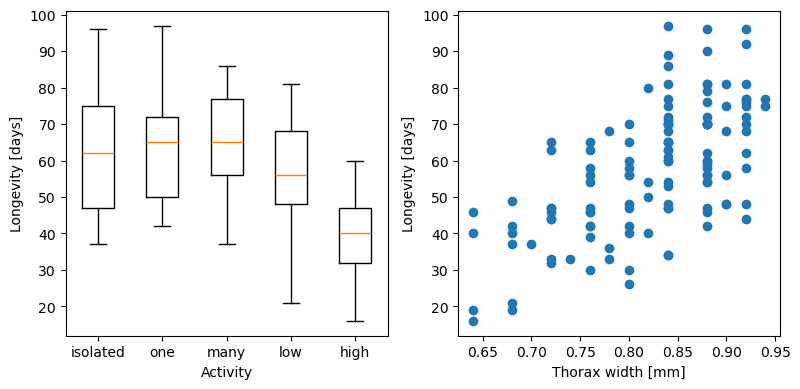

In [21]:
# Define the subplot layout
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

# First plot (boxplot)
axes[0].boxplot([fruitfly[fruitfly['activity'] == levels]['longevity'] for levels in fruitfly['activity'].unique()],
                labels=fruitfly['activity'].unique())
axes[0].set_xlabel('Activity')
axes[0].set_ylabel('Longevity [days]')
axes[0].set_title('')

# Second plot (scatter plot)
axes[1].scatter(fruitfly['thorax'], fruitfly['longevity'])
axes[1].set_xlabel('Thorax width [mm]')
axes[1].set_ylabel('Longevity [days]')
axes[1].set_title('')

# Adjust layout
plt.tight_layout()

# Show plots
plt.show()


## 1.3 Analysis

In [22]:
fm = ols("longevity ~ C(activity) * thorax", data=fruitfly).fit()

# Get the ANOVA summary
anova_results = anova_lm(fm)

# Print the ANOVA summary
anova_results


,df,sum_sq,mean_sq,F,PR(>F)
C(activity),4.0,12269.467151,3067.366788,26.727833,1.200318e-15
thorax,1.0,12368.420833,12368.420833,107.773577,3.565139e-18
C(activity):thorax,4.0,24.313592,6.078398,0.052965,9.946914e-01
Residual,114.0,13082.983907,114.763017,NaN,NaN


In [ ]:
model = pg.anova(dv="breaks", between=["wool", "tension"], data=warpbreaks).round(3)
model

So there is a clear effect of both predictors, and no indication of an interaction. <br>
To investigate which groups are actually different, we would use a post-hoc analysis, after removing the interaction:

In [23]:
# Update the model to remove the interaction term

# Fit the OLS model
fm2 = ols("longevity ~ C(activity) + thorax", data=fruitfly).fit()

# Perform Tukey multiple comparisons test for 'activity'
tukey_results = pairwise_tukeyhsd(fruitfly['longevity'], fruitfly['activity'], alpha=0.05)

# Get the summary of the test results
print(tukey_results)

   Multiple Comparison of Means - Tukey HSD, FWER=0.05   
 group1   group2  meandiff p-adj   lower    upper  reject
---------------------------------------------------------
    high isolated    24.84    0.0  13.3764 36.3036   True
    high      low    18.04 0.0003   6.5764 29.5036   True
    high     many  25.8217    0.0  14.2392 37.4041   True
    high      one    26.08    0.0  14.6164 37.5436   True
isolated      low     -6.8 0.4731 -18.2636  4.6636  False
isolated     many   0.9817 0.9993 -10.6008 12.5641  False
isolated      one     1.24 0.9982 -10.2236 12.7036  False
     low     many   7.7817 0.3441  -3.8008 19.3641  False
     low      one     8.04 0.3007  -3.4236 19.5036  False
    many      one   0.2583    1.0 -11.3241 11.8408  False
---------------------------------------------------------


##  1.4 Interpret statistical finding
Offering males a high number of copulation options substantially reduced longevity, from around 60 to 40 days, i.e. -30%. Isolating males, or enabling reproductively irrelevant copulations (isolated, one, many) were equivalent options. This suggests that male fruitflies only invest energy when there is a chance of reproduction, and that every such activity shortens the individual’s lifetime.

Larger males lived longer, up to five times as small males, but that effect was purely additive to the experimental
treatment.

# 1. Exercise 1 (10 points): Effect of temperature on sex in turtles
It is not uncommon, in plants, fish, crustaceans and reptiles, that [sex-determination is through environmental conditions](https://en.wikipedia.org/wiki/Environmental_sex_determination) during egg development. In this data set (**faraway**'s `turtle`), the number of male and female turtles emerging from eggs incubated at different temperatures is counted.

  1. Plot the data in a meaningful way. (**2 points**)
  2. Analyse the data, i.e. what is the probability of an female to emerge from an egg, given the temperature? (**2 points**)
  3. Plot the data and the fitted GLM, with 95\% confidence interval. (**2 points**)
  4. Compute at which temperature there will be exactly a 50:50 chance that the egg will yield a female turtle? (**2 points**)
  5. Interpret findings, including the previous step. (**2 points**)

In [3]:
turtle = pd.read_csv("turtle.csv")
turtle.describe()

,temp,male,female
count,15.000000,15.000000,15.000000
mean,28.300000,6.066667,3.000000
std,0.941883,3.514595,2.976095
min,27.200000,0.000000,0.000000
25%,27.700000,4.500000,1.000000
50%,28.300000,7.000000,2.000000
75%,28.400000,7.500000,3.000000
max,29.900000,13.000000,9.000000


## 2.1 Plot

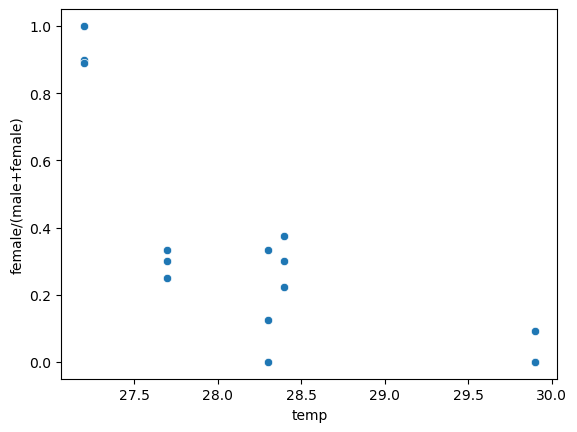

In [4]:
#plot

sns.scatterplot(x = turtle['temp'],
                y = turtle['female']/(turtle['male']+turtle['female']))
plt.ylabel('female/(male+female)')
plt.show()

## 2.2 Analyse

In [5]:
X = turtle['temp']
y = turtle[['female', 'male']]

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit logistic regression model
fm = sm.GLM(y, X, family=sm.families.Binomial()).fit()

# Print the summary of the model
print(fm.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:     ['female', 'male']   No. Observations:                   15
Model:                            GLM   Df Residuals:                       13
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -24.918
Date:                Tue, 12 Nov 2024   Deviance:                       24.942
Time:                        15:20:16   Pearson chi2:                     26.2
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9633
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         61.3183     12.022      5.100      0.0

In [6]:
## OR

X = turtle['temp']
y = turtle['female'] / (turtle['female'] + turtle['male'])
weights = turtle['female'] + turtle['male']

# Add a constant term for the intercept
X = sm.add_constant(X)

# Fit logistic regression model
fm2 = sm.GLM(y, X, family=sm.families.Binomial(), freq_weights=weights).fit()


# Print the summary of the model
print(fm2.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:                      y   No. Observations:                   15
Model:                            GLM   Df Residuals:                      134
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -45.918
Date:                Tue, 12 Nov 2024   Deviance:                       24.942
Time:                        15:21:16   Pearson chi2:                     26.2
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9633
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         61.3183     12.022      5.100      0.0

In [7]:
## OR (like R-way)

turtle2 = turtle.copy()
turtle2['response'] = turtle2['female'] / (turtle2['female'] + turtle2['male'])
turtle2['weights'] = turtle['female'] + turtle['male']

# Define the formula
formula = "response ~ temp"

# Fit the GLM
fm3 = sm.GLM.from_formula(formula, family=sm.families.Binomial(),freq_weights=weights, data=turtle2).fit() 

# Print the summary
print(fm3.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               response   No. Observations:                   15
Model:                            GLM   Df Residuals:                      134
Model Family:                Binomial   Df Model:                            1
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -45.918
Date:                Tue, 12 Nov 2024   Deviance:                       24.942
Time:                        15:22:15   Pearson chi2:                     26.2
No. Iterations:                     6   Pseudo R-squ. (CS):             0.9633
Covariance Type:            nonrobust                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     61.3183     12.022      5.100      0.0

## 2.3 Plot with regression line

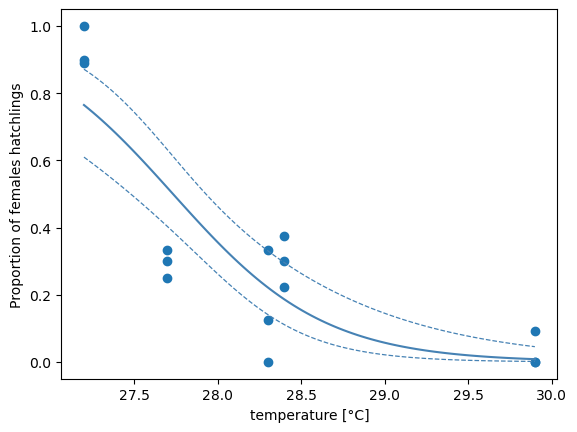

In [8]:
plt.scatter(turtle2['temp'], turtle2['response'])
plt.ylabel("Proportion of females hatchlings")
plt.xlabel("temperature [°C]")

newTemp = np.linspace(min(turtle['temp']), max(turtle['temp']), num=100)
newTemp_df = pd.DataFrame(list(newTemp), columns=["temp"])

preds = fm3.get_prediction(newTemp_df).summary_frame(alpha=0.05)

plt.plot(newTemp, preds['mean'], color='steelblue')
plt.plot(newTemp, preds['mean_ci_upper'], color='steelblue',linestyle='--',linewidth=0.9)
plt.plot(newTemp, preds['mean_ci_lower'], color='steelblue',linestyle='--',linewidth=0.9)
plt.show()

## 2.4 Temperature of P(female | temperature) = 0.5


*Alternatively, reformulate the GLM equation:*
$$\log(P(\text{female})) = \log(0.5) = 0 = 61.3 - 2.21t$$

$$ \Longleftrightarrow t = 61.3 / 2.21 =  27.74$$

*To get the standard error for this estimate, you have to use equations from [propagation of uncertainty](https://en.wikipedia.org/wiki/Propagation_of_uncertainty#Example_formulae), which takes us too far and is not part of the question.*

$$ f = A/B = \frac{61.3\pm12.02}{2.21 \pm 0.431}$$

We will need the covariance of the two estimates (intercept and temperature):

In [9]:
# Get the variance-covariance matrix
var_cov_matrix = fm.cov_params()

# Print the variance-covariance matrix
print(var_cov_matrix)


            const      temp
const  144.538239 -5.179042
temp    -5.179042  0.185637


$$\text{Then: } \sigma^2_f \approx  f^2 \left ( \frac{\sigma_A^2}{A^2} + \frac{\sigma_B^2}{B^2} - \frac{2\sigma_{AB}}{AB} \right )$$

$$ = 27.74^2(12.0224^2/61.32^2 + 0.4309^2/2.211^2 - 2\cdot(-5.179)/(61.32\cdot -2.211)) $$

$$ = 769.5\cdot (0.03844+0.03798- 0.07639) = 0.023085$$

$$ \Longrightarrow \sigma_f = \sqrt{0.023085} = 0.152.$$

This value is somewhat too high, largely because I rounded too early. (This is relevant, because the partial errors and the partial covariance almost exactly cancel, so that every digit counts.) But you get the gist, I hope.


## 1.5 Interpretation

The data suggest a strong temperature-dependence of sex determination, switching from largely females at temperatures below 27°C to almost exclusively male above 29°C (P < 0.0001). The proportion of females is 50% at a temperature of  27.7±0.11
 °C.